# BƯỚC 4 & 5: ELBOW METHOD, TÁI TẠO ẢNH ĐỘ PHÂN GIẢI GỐC VÀ SO SÁNH SIDE-BY-SIDE

Quét dải số cụm $K \in [2, 12]$ bằng `Scikit-Learn KMeans`, chọn $K$ tối ưu bằng thuật toán Kneedle, trực quan hóa lưới tiến hóa theo $K$, phục hồi ảnh phân đoạn ở đúng kích thước gốc $(H, W, 3)$, trích xuất ranh giới cụm và thống kê tỷ lệ màu sắc chủ đạo.

> **Lưu ý:** Toàn bộ kết quả (bảng và hình ảnh) chỉ lưu ngay trong notebook này, không ghi đè vào `results/` của `main.py`.

### 1. Nạp module và chuẩn bị dữ liệu đầu vào

In [1]:
import io
import sys
from pathlib import Path

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import DEFAULT_IMAGE_PATH, FIGURE_DPI, K_SEARCH_RANGE, MAX_ITER, N_INIT, RANDOM_SEED, TARGET_SIZE
from src.data.loader import load_image
from src.data.preprocessing import flatten_pixels, resize_image
from src.features.color_features import extract_color_distribution
from src.models.kmeans_sklearn import SklearnKMeansTrainer
from src.segmentation.segmenter import ImageSegmenter

def show_figure(fig):
    """Hiển thị trực tiếp đối tượng matplotlib Figure dưới dạng PNG ngay trong notebook."""
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=FIGURE_DPI, bbox_inches='tight')
    plt.close(fig)
    display(Image(data=buf.getvalue()))

img_rgb, metadata = load_image(DEFAULT_IMAGE_PATH)
resized_rgb, resized_shape = resize_image(img_rgb, target_size=TARGET_SIZE)
pixel_matrix = flatten_pixels(resized_rgb, as_float=True)
print(f"Ảnh gốc: {img_rgb.shape[1]}x{img_rgb.shape[0]} | Ảnh làm việc: {resized_shape[1]}x{resized_shape[0]}")

Ảnh gốc: 3264x3264 | Ảnh làm việc: 256x256


### 2. Quét Elbow Method (K=2..12), tìm K tối ưu & Lưới tiến hóa theo K

Số cụm K tối ưu do Kneedle xác định: K = 5


,K,Inertia,N_Iter,Fit_Time_Sec
0,2,334192736.0,10,0.3551
1,3,232993008.0,6,0.2905
2,4,156334944.0,18,0.4464
3,5,121024704.0,7,0.4101
4,6,104840664.0,10,0.5567
5,7,90721552.0,23,0.5310
6,8,78616968.0,51,0.6847
7,9,70459792.0,32,0.7183
8,10,64329860.0,37,0.8079
9,11,58793260.0,31,1.0552


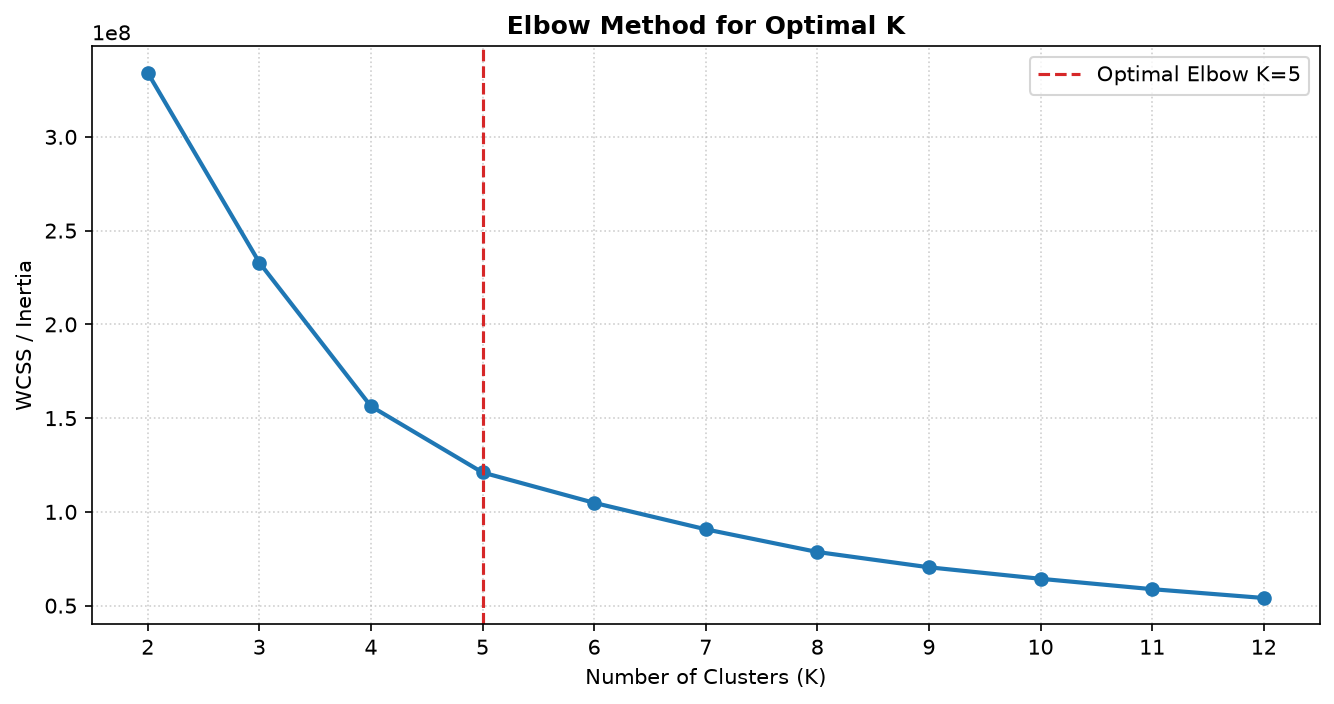

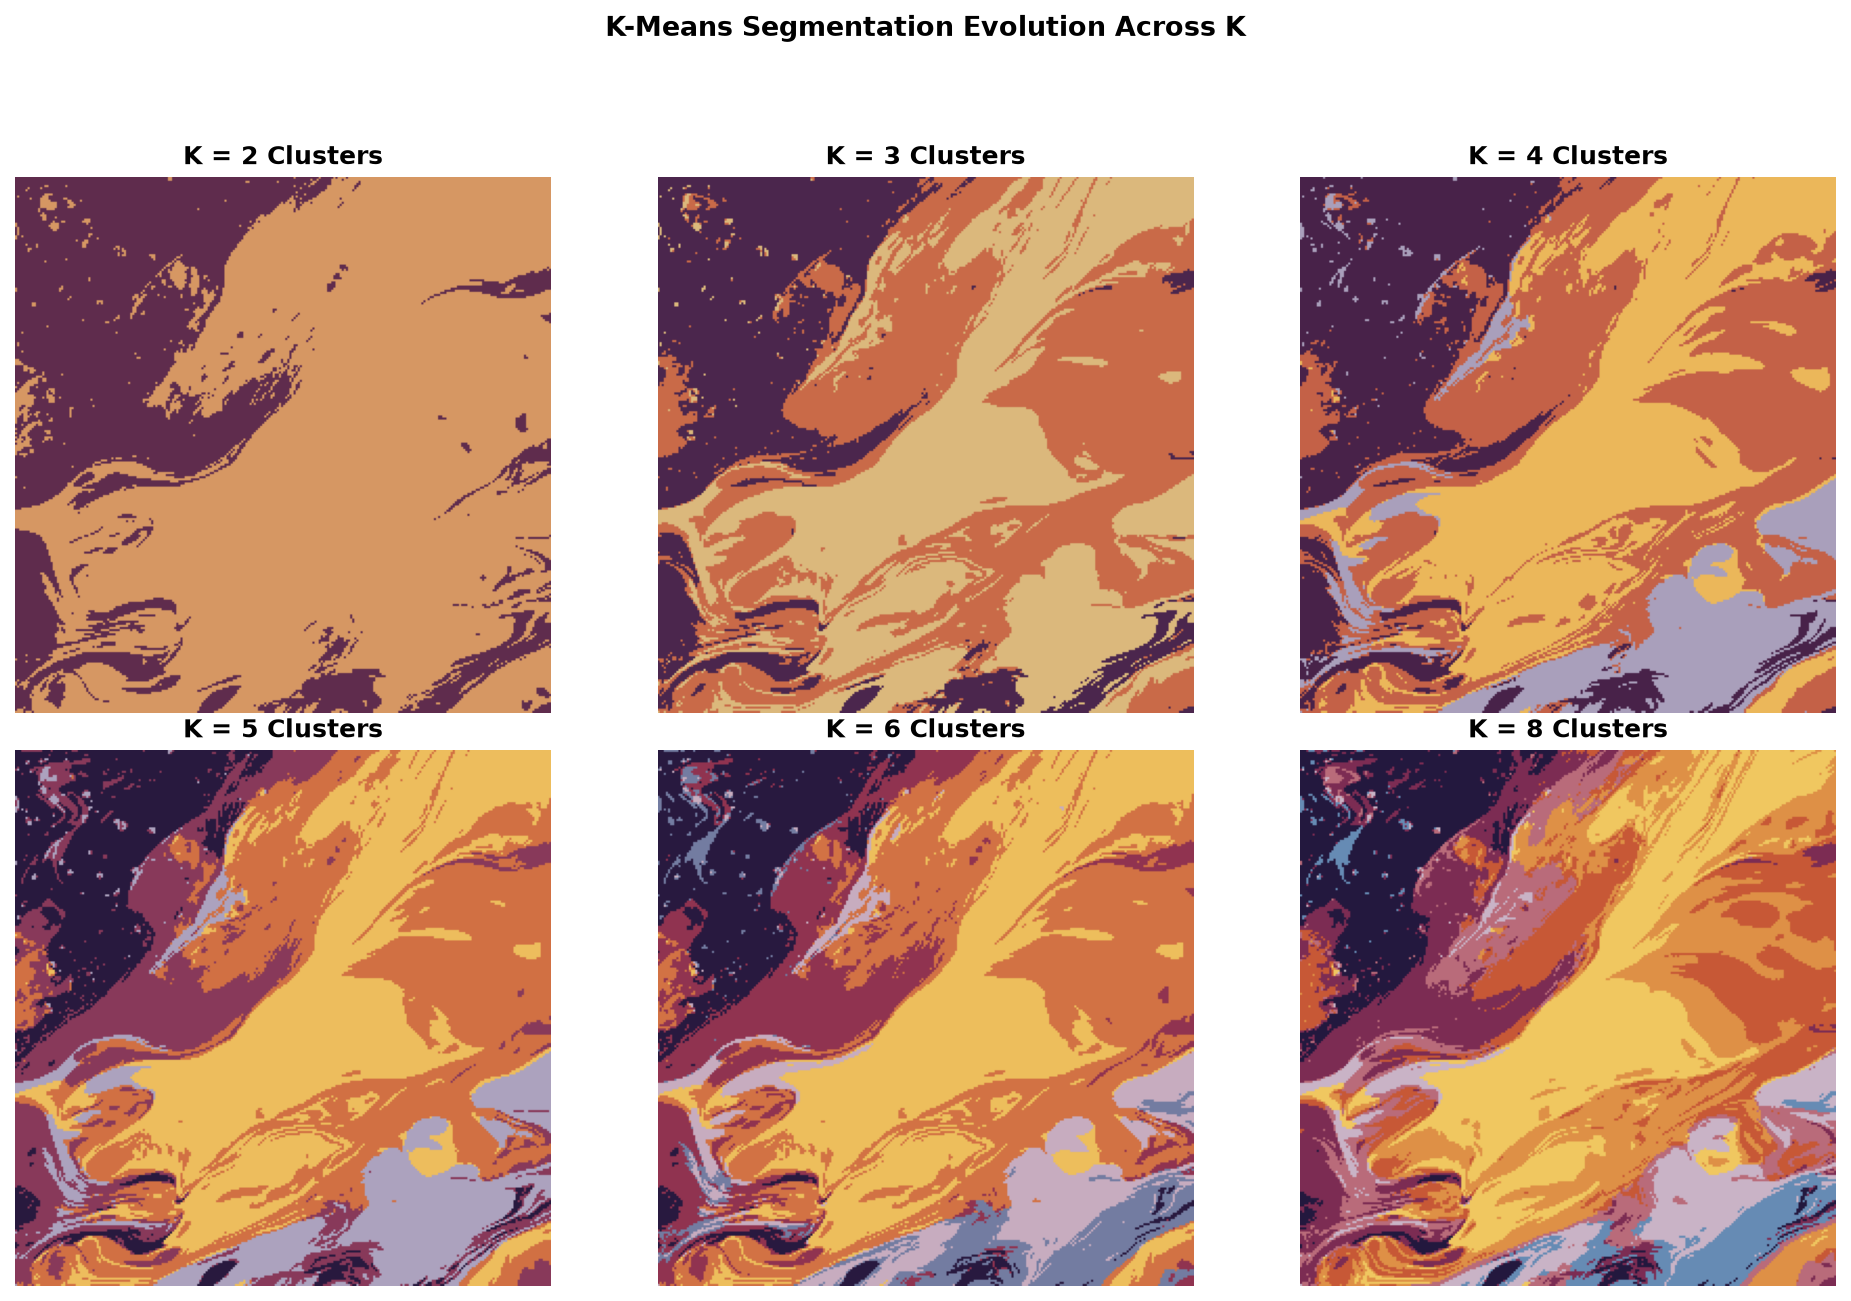

In [2]:
trainer = SklearnKMeansTrainer(random_state=RANDOM_SEED)
df_elbow, optimal_k = trainer.search_elbow(pixel_matrix, k_range=K_SEARCH_RANGE)
print(f"Số cụm K tối ưu do Kneedle xác định: K = {optimal_k}")
display(df_elbow)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(df_elbow['K'], df_elbow['Inertia'], marker='o', linewidth=2, color='#1f77b4')
ax.axvline(x=optimal_k, color='#d62728', linestyle='--', label=f'Optimal Elbow K={optimal_k}')
ax.set_title('Elbow Method for Optimal K', fontweight='bold')
ax.set_xlabel('Number of Clusters (K)')
ax.set_ylabel('WCSS / Inertia')
ax.set_xticks(df_elbow['K'].to_numpy())
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
fig.tight_layout()
show_figure(fig)

final_model = trainer.fit_final_model(pixel_matrix, optimal_k=optimal_k, n_init=N_INIT, max_iter=MAX_ITER)
segmenter = ImageSegmenter()
k_candidates = sorted({2, 3, 4, optimal_k, 6, 8})
fig_grid, axes_grid = plt.subplots(2, 3, figsize=(13, 8.8))
for ax_g, k_val in zip(axes_grid.ravel(), k_candidates):
    m_k = final_model if k_val == optimal_k else trainer.fit_final_model(pixel_matrix, optimal_k=k_val, n_init=5, max_iter=150)
    seg_k = segmenter.reconstruct_segmented_image(m_k.labels_, m_k.cluster_centers_, target_shape=resized_shape)
    ax_g.imshow(seg_k)
    ax_g.set_title(f'K = {k_val} Clusters', fontweight='bold')
    ax_g.axis('off')
fig_grid.suptitle('K-Means Segmentation Evolution Across K', fontsize=13, fontweight='bold', y=0.98)
fig_grid.tight_layout(rect=[0.0, 0.0, 1.0, 0.93])
show_figure(fig_grid)

### 3. Phân đoạn toàn ảnh độ phân giải gốc, Ranh giới cụm & Hiển thị Side-by-Side

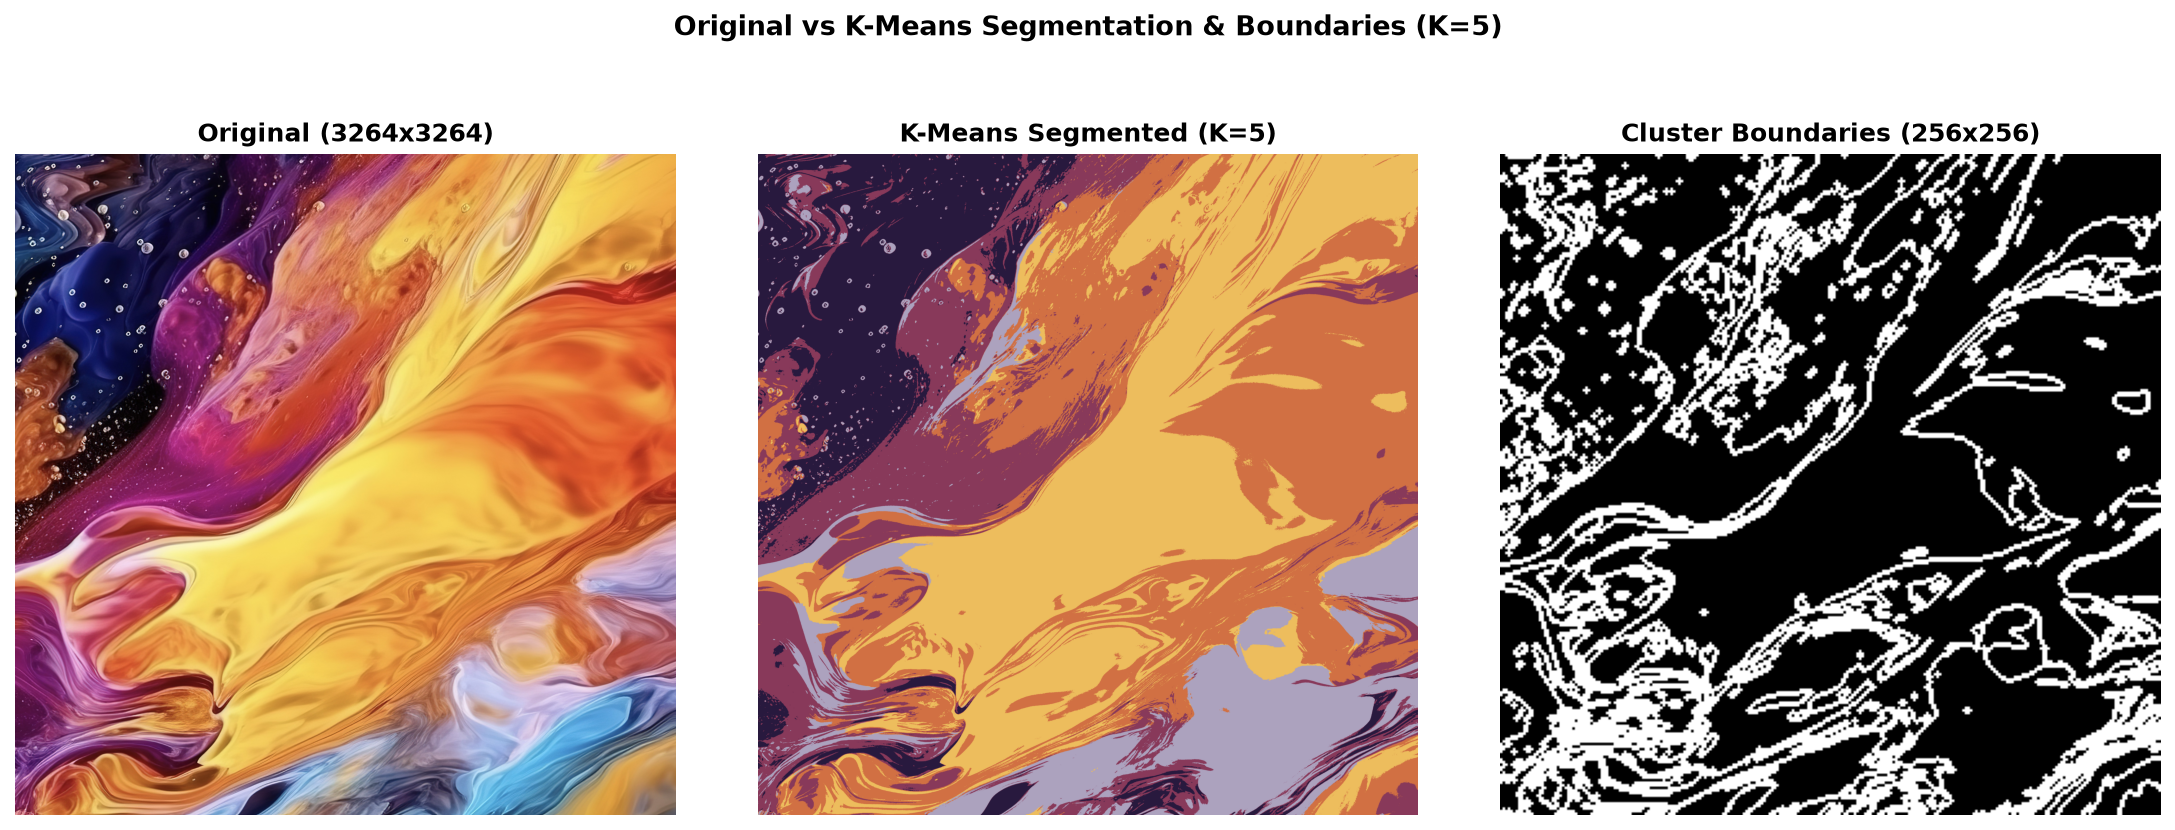

In [3]:
orig_pixels = flatten_pixels(img_rgb, as_float=True)
labels_orig = np.empty(orig_pixels.shape[0], dtype=np.int64)
for start in range(0, orig_pixels.shape[0], 250000):
    end = min(start + 250000, orig_pixels.shape[0])
    labels_orig[start:end] = final_model.predict(orig_pixels[start:end])

segmented_orig = segmenter.reconstruct_segmented_image(
    labels_orig, final_model.cluster_centers_, target_shape=(img_rgb.shape[0], img_rgb.shape[1])
)
boundaries = segmenter.extract_cluster_boundaries(final_model.labels_, shape=resized_shape)

fig, axes = plt.subplots(1, 3, figsize=(15, 5.6))
axes[0].imshow(img_rgb)
axes[0].set_title(f'Original ({img_rgb.shape[1]}x{img_rgb.shape[0]})', fontweight='bold')
axes[0].axis('off')
axes[1].imshow(segmented_orig)
axes[1].set_title(f'K-Means Segmented (K={optimal_k})', fontweight='bold')
axes[1].axis('off')
axes[2].imshow(boundaries, cmap='gray')
axes[2].set_title(f'Cluster Boundaries ({resized_shape[1]}x{resized_shape[0]})', fontweight='bold')
axes[2].axis('off')
fig.suptitle(f'Original vs K-Means Segmentation & Boundaries (K={optimal_k})', fontsize=13, fontweight='bold', y=0.98)
fig.tight_layout(rect=[0.0, 0.0, 1.0, 0.90])
show_figure(fig)

### 4. Thống kê & Biểu đồ phân bố tỷ lệ các cụm màu chủ đạo

,Rank,Cluster ID,Color Name,HEX,Pixels,Share (%)
0,1,0,Cam rực (Orange),#D17043,3139461,29.47
1,2,2,Cam vàng (Yellow-Orange),#EDBD5D,2948244,27.67
2,3,1,Đỏ mận (Magenta-Red),#88395A,1844562,17.31
3,4,4,Tím than (Dark-Violet),#28193E,1425227,13.38
4,5,3,Xám nhạt (Light Gray),#ACA2BE,1296202,12.17


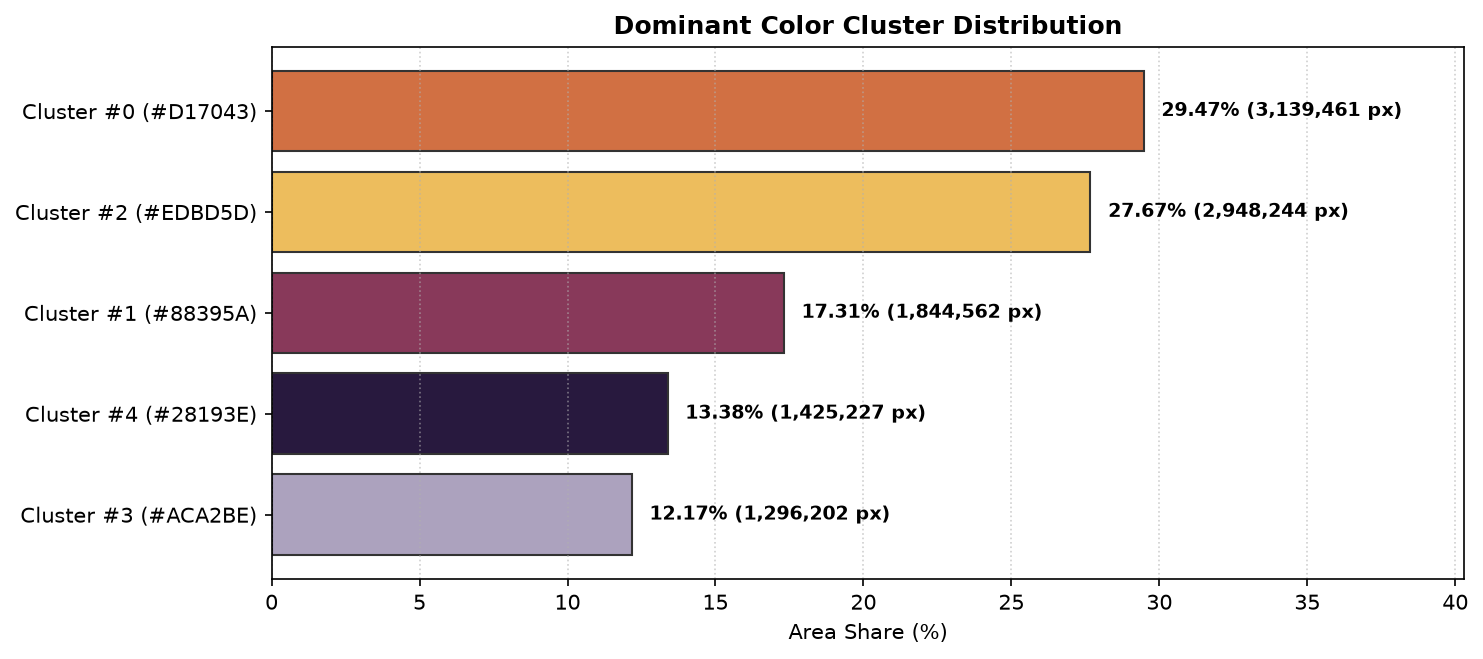

In [4]:
stats = extract_color_distribution(labels_orig, final_model.cluster_centers_)
df_stats = pd.DataFrame([
    {
        'Rank': item['dominance_rank'],
        'Cluster ID': item['cluster_id'],
        'Color Name': item['color_name'],
        'HEX': item['hex_color'],
        'Pixels': item['pixel_count'],
        'Share (%)': item['share_percentage'],
    }
    for item in stats
])
display(df_stats)

ordered = sorted(stats, key=lambda x: x['share_percentage'])
fig_dist, ax_d = plt.subplots(figsize=(10, 4.5))
y_labels = [f"Cluster #{x['cluster_id']} ({x['hex_color']})" for x in ordered]
pcts = [x['share_percentage'] for x in ordered]
colors = [tuple(np.clip(np.asarray(x['centroid_rgb']) / 255.0, 0.0, 1.0)) for x in ordered]
bars = ax_d.barh(y_labels, pcts, color=colors, edgecolor='#333333')
for b, x in zip(bars, ordered):
    ax_d.text(b.get_width() + 0.6, b.get_y() + b.get_height()/2, f"{x['share_percentage']:.2f}% ({x['pixel_count']:,} px)", va='center', fontweight='bold', fontsize=9)
ax_d.set_xlim(0, max(pcts) * 1.3 + 2)
ax_d.set_title('Dominant Color Cluster Distribution', fontweight='bold')
ax_d.set_xlabel('Area Share (%)')
ax_d.grid(axis='x', linestyle=':', alpha=0.6)
fig_dist.tight_layout()
show_figure(fig_dist)